# Phase 3, Phase 4 & Phase 5: Data Cleaning, Feature Engineering, Train-Test Split & Preprocessing

**Project:** Health Insurance Cross-Sell Prediction Using Machine Learning  

In this notebook, we follow a leakage-free Machine Learning workflow:
1. **Phase 3 (Data Cleaning):** Check missing values, duplicates, data types, invalid values, and analyze numerical outliers with boxplots.
2. **Phase 4 (Feature Engineering):** Remove `id`, inspect `Region_Code` and `Policy_Sales_Channel` as categorical codes, design encodings for `Gender`, `Vehicle_Age`, and `Vehicle_Damage`, and check multicollinearity (VIF).
3. **Phase 7 (Train-Test Split — Before Fitting Preprocessing):** Split data into **80% training** and **20% testing** (`random_state=42`, `stratify=y`) so the test set remains completely unseen.
4. **Phase 5 (Data Preprocessing Pipeline):** Build a Scikit-learn `ColumnTransformer` that imputes, scales, and encodes features, fit it **only on `X_train`**, and verify transformed outputs on `X_train` and `X_test`.

## Step 1: Import Libraries & Load Dataset

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder, FunctionTransformer

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 150

RANDOM_STATE = 42
DATA_PATH = os.path.join('..', 'Dataset', 'train.csv')
GRAPHS_DIR = os.path.join('..', 'Outputs', 'graphs')
os.makedirs(GRAPHS_DIR, exist_ok=True)

df = pd.read_csv(DATA_PATH)
print(f'Loaded raw dataset: {df.shape[0]:,} rows x {df.shape[1]} columns')

Loaded raw dataset: 381,109 rows x 12 columns


--- 
# PHASE 3: DATA CLEANING

## 3.1 Missing Values & Duplicate Records

We check:
- Missing values per column.
- Exact duplicate rows across all 12 columns.
- Feature-level duplicates (excluding `id`) to see if different customers simply share identical profile values (e.g., same age and base minimum premium `2630.0`).

In [2]:
print('Missing values per column:')
print(df.isnull().sum())

exact_dups = df.duplicated().sum()
feature_dups = df.drop(columns=['id']).duplicated().sum()
print(f'\nExact duplicate rows (including id): {exact_dups}')
print(f'Rows sharing identical feature+target values (excluding id): {feature_dups}')

# Inspect why feature_dups exist
dup_rows = df[df.drop(columns=['id']).duplicated(keep=False)]
print('Top Annual_Premium values among those rows:')
print(dup_rows['Annual_Premium'].value_counts().head(3))

Missing values per column:
id                      0
Gender                  0
Age                     0
Driving_License         0
Region_Code             0
Previously_Insured      0
Vehicle_Age             0
Vehicle_Damage          0
Annual_Premium          0
Policy_Sales_Channel    0
Vintage                 0
Response                0
dtype: int64



Exact duplicate rows (including id): 0
Rows sharing identical feature+target values (excluding id): 269
Top Annual_Premium values among those rows:
Annual_Premium
2630.0     536
42426.0      2
Name: count, dtype: int64


**Cleaning Decision (Duplicates):**
- There are **0 exact duplicates** and **0 duplicate customer IDs**.
- The 269 rows sharing identical attributes (almost all at the minimum base premium `2630.0`) have distinct `id`s and represent different real customers who happen to share common demographic/policy profiles. Therefore, we **retain** all rows.

## 3.2 Data Type Verification & Correction

`Region_Code` and `Policy_Sales_Channel` were loaded as `float64` (e.g. `28.0`, `152.0`) even though they represent discrete category codes. We verify that every value is an exact integer and convert them to clean integer-string codes so Pandas and Scikit-learn treat them strictly as categorical IDs.

In [3]:
# Verify Region_Code and Policy_Sales_Channel have zero fractional parts
region_is_int = (df['Region_Code'] % 1 == 0).all()
channel_is_int = (df['Policy_Sales_Channel'] % 1 == 0).all()
print(f'All Region_Code values are whole numbers         : {region_is_int}')
print(f'All Policy_Sales_Channel values are whole numbers: {channel_is_int}')

# Convert to clean string category codes (e.g. 28.0 -> '28')
df['Region_Code'] = df['Region_Code'].astype(int).astype(str)
df['Policy_Sales_Channel'] = df['Policy_Sales_Channel'].astype(int).astype(str)
print('Converted Region_Code and Policy_Sales_Channel to clean string category codes.')

All Region_Code values are whole numbers         : True
All Policy_Sales_Channel values are whole numbers: True


Converted Region_Code and Policy_Sales_Channel to clean string category codes.


## 3.3 Unusual or Invalid Values Check

We validate domain boundaries for every column:
- `Age` should be plausible adult ages (e.g., >= 18 and <= 100).
- `Annual_Premium` should be strictly positive (`> 0`).
- `Vintage` should be non-negative (`>= 0`).
- Binary flags (`Driving_License`, `Previously_Insured`, `Response`) must contain only `0` and `1`.
- Categorical text columns must contain only expected valid labels.

In [4]:
print('Age min/max               :', df['Age'].min(), 'to', df['Age'].max())
print('Annual_Premium <= 0 count :', (df['Annual_Premium'] <= 0).sum())
print('Vintage < 0 count         :', (df['Vintage'] < 0).sum())
print('Gender unique             :', df['Gender'].unique().tolist())
print('Vehicle_Age unique        :', df['Vehicle_Age'].unique().tolist())
print('Vehicle_Damage unique     :', df['Vehicle_Damage'].unique().tolist())
print('Driving_License unique    :', sorted(df['Driving_License'].unique().tolist()))
print('Previously_Insured unique :', sorted(df['Previously_Insured'].unique().tolist()))
print('Response unique           :', sorted(df['Response'].unique().tolist()))

Age min/max               : 20 to 85
Annual_Premium <= 0 count : 0
Vintage < 0 count         : 0
Gender unique             : ['Male', 'Female']
Vehicle_Age unique        : ['> 2 Years', '1-2 Year', '< 1 Year']
Vehicle_Damage unique     : ['Yes', 'No']
Driving_License unique    : [0, 1]
Previously_Insured unique : [0, 1]
Response unique           : [0, 1]


**Cleaning Decision (Validity):** Every column falls strictly within valid domain limits; no corrupted or impossible values were found.

## 3.4 Outlier Analysis and Boxplot Visualization

We check outliers in the three continuous numerical features (`Age`, `Annual_Premium`, `Vintage`) using the Interquartile Range (IQR) rule (`Q1 - 1.5*IQR` to `Q3 + 1.5*IQR`) and visualize them using boxplots.

,Feature,Q1,Q3,IQR,Lower_Fence,Upper_Fence,Below_Count,Above_Count,Outlier_Pct (%)
0,Age,25.0,49.0,24.0,-11.0,85.0,0,0,0.00
1,Annual_Premium,24405.0,39400.0,14995.0,1912.5,61892.5,0,10320,2.71
2,Vintage,82.0,227.0,145.0,-135.5,444.5,0,0,0.00


High Annual_Premium (> 61,892.5) interest rate: 15.07%
Normal Annual_Premium (<= 61,892.5) interest rate: 12.18%


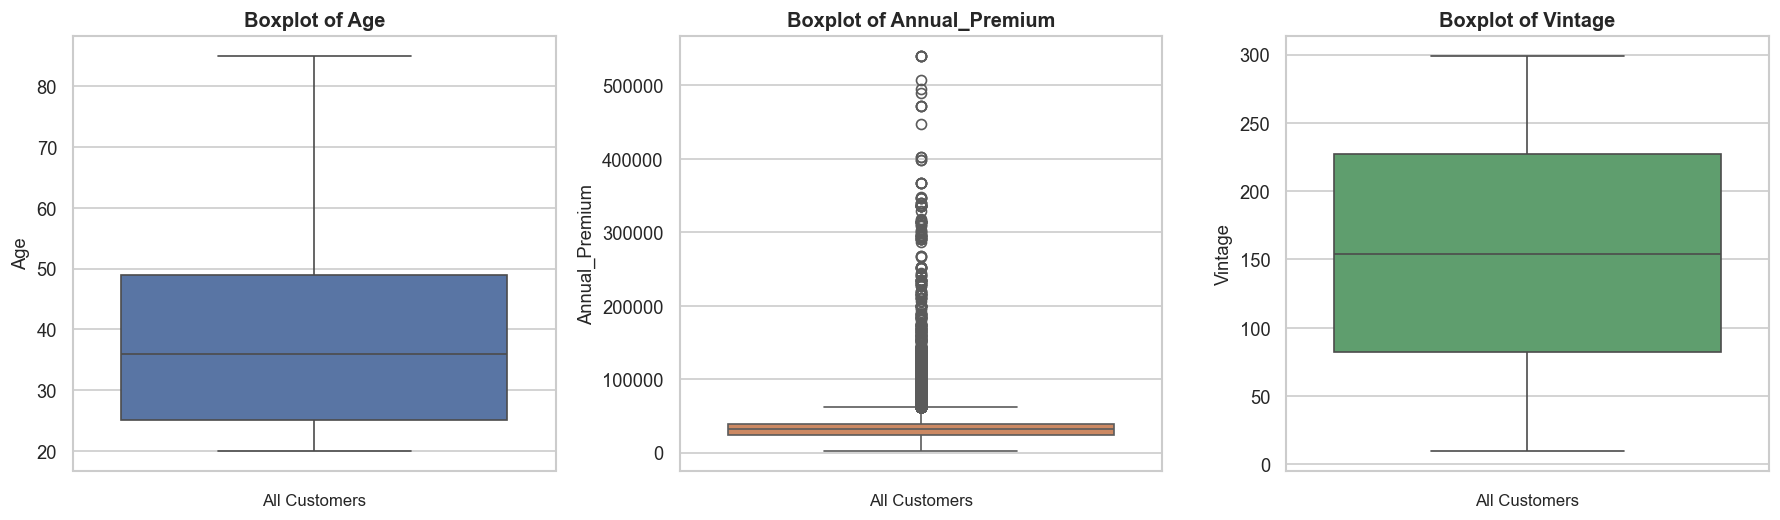

In [5]:
num_cols = ['Age', 'Annual_Premium', 'Vintage']

# Compute IQR outlier statistics
outlier_rows = []
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_below = int((df[col] < lower).sum())
    n_above = int((df[col] > upper).sum())
    outlier_rows.append({
        'Feature': col, 'Q1': q1, 'Q3': q3, 'IQR': iqr,
        'Lower_Fence': lower, 'Upper_Fence': upper,
        'Below_Count': n_below, 'Above_Count': n_above,
        'Outlier_Pct (%)': round((n_below + n_above) / len(df) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_rows)
display(outlier_df)

# Inspect response rate for high-premium outliers vs normal premiums
upper_prem = outlier_df.loc[outlier_df['Feature'] == 'Annual_Premium', 'Upper_Fence'].values[0]
high_prem_mask = df['Annual_Premium'] > upper_prem
print(f"High Annual_Premium (> {upper_prem:,.1f}) interest rate: {df.loc[high_prem_mask, 'Response'].mean()*100:.2f}%")
print(f"Normal Annual_Premium (<= {upper_prem:,.1f}) interest rate: {df.loc[~high_prem_mask, 'Response'].mean()*100:.2f}%")

# Visualize boxplots
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
colors = ['#4C72B0', '#DD8452', '#55A868']
for ax, col, c in zip(axes, num_cols, colors):
    sns.boxplot(y=df[col], color=c, ax=ax)
    ax.set_title(f'Boxplot of {col}', fontsize=12, fontweight='bold')
    ax.set_ylabel(col, fontsize=11)
    ax.set_xlabel('All Customers', fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, '14_numerical_outliers_boxplots.png'))
plt.show()

**Outlier Handling Decision:**
- `Age` and `Vintage` have **0 outliers** (`0.00%`).
- `Annual_Premium` has **10,320 upper-tail values (`2.71%`)** above the IQR fence (`61,892.5`), reaching up to `540,165.0`. Notably, these high-premium customers have a **15.07%** interest rate compared to **12.18%** for the rest — meaning they are genuine high-value/family-plan customers rather than errors.
- **Decision:** We **retain all 10,320 records** instead of deleting them. To prevent extreme values from distorting linear models (like Logistic Regression) while preserving exact rank order for tree models, we apply a monotonic **`log1p` transformation** (`np.log1p`) followed by `StandardScaler` inside our preprocessing pipeline.

---
# PHASE 4: FEATURE ENGINEERING & MULTICOLLINEARITY CHECK

1. **Drop `id`**: Customer ID is an arbitrary row counter (`1` to `381,109`) with no predictive signal.
2. **Categorical Variable Strategy:**
   - `Gender` (`Male`, `Female`) & `Vehicle_Damage` (`Yes`, `No`): Binary categorical features -> `OneHotEncoder(drop='if_binary')` converts them cleanly into `0`/`1`.
   - `Vehicle_Age` (`< 1 Year`, `1-2 Year`, `> 2 Years`): Has a clear natural order (`0 < 1 < 2`) -> `OrdinalEncoder` preserves this progression.
   - `Region_Code` (53 categories) & `Policy_Sales_Channel` (155 categories): Numeric codes representing nominal categories -> `OneHotEncoder(handle_unknown='ignore', min_frequency=0.01)` creates binary indicators for frequent regions/channels (>= 1% of training data) and groups rare codes into a single `infrequent` column. This prevents creating 200+ sparse columns while avoiding target leakage.
3. **No Unnecessary Features:** We avoid inventing artificial features that add noise without clear domain justification.
4. **Multicollinearity Check (VIF):** We inspect Variance Inflation Factor (VIF) on numerical & binary predictors to ensure linear models will not suffer from unstable coefficients.

In [6]:
# Compute Variance Inflation Factor (VIF) on numerical/binary features using only NumPy/Pandas
# VIF_j = 1 / (1 - R^2_j) where R^2_j comes from regressing feature j on all other features
from sklearn.linear_model import LinearRegression

vif_cols = ['Age', 'Driving_License', 'Previously_Insured', 'Annual_Premium', 'Vintage']
X_vif = df[vif_cols].copy()
X_vif['Annual_Premium'] = np.log1p(X_vif['Annual_Premium'])

vif_results = []
for col in vif_cols:
    other_cols = [c for c in vif_cols if c != col]
    reg = LinearRegression().fit(X_vif[other_cols], X_vif[col])
    r2 = reg.score(X_vif[other_cols], X_vif[col])
    vif = 1.0 / (1.0 - r2)
    vif_results.append({'Feature': col, 'R2_with_others': round(r2, 4), 'VIF': round(vif, 4)})

print('--- Multicollinearity Check (VIF) ---')
display(pd.DataFrame(vif_results))

--- Multicollinearity Check (VIF) ---


,Feature,R2_with_others,VIF
0,Age,0.0707,1.0760
1,Driving_License,0.0064,1.0065
2,Previously_Insured,0.0678,1.0727
3,Annual_Premium,0.0032,1.0032
4,Vintage,0.0000,1.0000


**Multicollinearity Interpretation:** All VIF values are well below `1.2` (the standard concern threshold is `VIF > 5` or `10`), confirming there is **no problematic multicollinearity** among the numerical and binary predictors.

---
# PHASE 7 & PHASE 5: TRAIN-TEST SPLIT (80/20) & LEAKAGE-FREE PREPROCESSING PIPELINE

We split the data **before** fitting any scaler or encoder so that zero statistical information from the 20% test set leaks into training:
- `test_size = 0.20` (80% train, 20% test)
- `random_state = 42` (reproducibility)
- `stratify = y` (preserves the exact `12.26%` positive class ratio in both train and test sets)

In [7]:
# Separate features (X) and target (y), dropping 'id'
X = df.drop(columns=['id', 'Response'])
y = df['Response']

# Stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f'X_train shape: {X_train.shape}, y_train positive rate: {y_train.mean()*100:.2f}% ({y_train.sum():,} positives)')
print(f'X_test  shape: {X_test.shape}, y_test  positive rate: {y_test.mean()*100:.2f}% ({y_test.sum():,} positives)')

X_train shape: (304887, 10), y_train positive rate: 12.26% (37,368 positives)
X_test  shape: (76222, 10), y_test  positive rate: 12.26% (9,342 positives)


Now we build the `ColumnTransformer` preprocessing pipeline and fit it **only on `X_train`**:
- `['Age', 'Vintage']`: median imputation + `StandardScaler()`
- `['Annual_Premium']`: median imputation + `log1p` transform + `StandardScaler()`
- `['Driving_License', 'Previously_Insured']`: most-frequent imputation (kept as 0/1)
- `['Vehicle_Age']`: most-frequent imputation + `OrdinalEncoder` (`< 1 Year` -> 0, `1-2 Year` -> 1, `> 2 Years` -> 2)
- `['Gender', 'Vehicle_Damage']`: most-frequent imputation + `OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False)`
- `['Region_Code', 'Policy_Sales_Channel']`: most-frequent imputation + `OneHotEncoder(handle_unknown='ignore', min_frequency=0.01, sparse_output=False)`

In [8]:
std_num_cols = ['Age', 'Vintage']
log_num_cols = ['Annual_Premium']
binary_num_cols = ['Driving_License', 'Previously_Insured']
ordinal_cat_cols = ['Vehicle_Age']
binary_cat_cols = ['Gender', 'Vehicle_Damage']
high_card_cat_cols = ['Region_Code', 'Policy_Sales_Channel']

std_num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

log_num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('scaler', StandardScaler())
])

binary_num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent'))
])

ordinal_cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(categories=[['< 1 Year', '1-2 Year', '> 2 Years']]))
])

binary_cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False))
])

high_card_cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(handle_unknown='ignore', min_frequency=0.01, sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('std_num', std_num_pipe, std_num_cols),
        ('log_num', log_num_pipe, log_num_cols),
        ('bin_num', binary_num_pipe, binary_num_cols),
        ('ord_cat', ordinal_cat_pipe, ordinal_cat_cols),
        ('bin_cat', binary_cat_pipe, binary_cat_cols),
        ('high_cat', high_card_cat_pipe, high_card_cat_cols)
    ],
    remainder='drop'
)

# Fit ONLY on X_train, then transform both X_train and X_test
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
print(f'Transformed X_train shape: {X_train_processed.shape}')
print(f'Transformed X_test  shape: {X_test_processed.shape}')
print(f'Total engineered features: {len(feature_names)}')
print(f'Any NaNs in X_train_processed: {np.isnan(X_train_processed).any()}')
print(f'Any NaNs in X_test_processed : {np.isnan(X_test_processed).any()}')
print('\nFirst 15 feature names:', feature_names[:15].tolist())
print('Last 15 feature names :', feature_names[-15:].tolist())

Transformed X_train shape: (304887, 44)
Transformed X_test  shape: (76222, 44)
Total engineered features: 44
Any NaNs in X_train_processed: False
Any NaNs in X_test_processed : False

First 15 feature names: ['std_num__Age', 'std_num__Vintage', 'log_num__Annual_Premium', 'bin_num__Driving_License', 'bin_num__Previously_Insured', 'ord_cat__Vehicle_Age', 'bin_cat__Gender_Male', 'bin_cat__Vehicle_Damage_Yes', 'high_cat__Region_Code_10', 'high_cat__Region_Code_11', 'high_cat__Region_Code_13', 'high_cat__Region_Code_14', 'high_cat__Region_Code_15', 'high_cat__Region_Code_18', 'high_cat__Region_Code_2']
Last 15 feature names : ['high_cat__Region_Code_48', 'high_cat__Region_Code_50', 'high_cat__Region_Code_6', 'high_cat__Region_Code_8', 'high_cat__Region_Code_infrequent_sklearn', 'high_cat__Policy_Sales_Channel_122', 'high_cat__Policy_Sales_Channel_124', 'high_cat__Policy_Sales_Channel_151', 'high_cat__Policy_Sales_Channel_152', 'high_cat__Policy_Sales_Channel_154', 'high_cat__Policy_Sales_Ch